# Step 1 : Import Required Libraries

In [1]:
import pandas as pd
import numpy as np

# Step 2 : Load Dataset

In [2]:
X_train = pd.read_csv("../Dataset/X_train_scaled.csv")
X_test = pd.read_csv("../Dataset/X_test_scaled.csv")

y_train = pd.read_csv("../Dataset/y_train.csv").squeeze()
y_test = pd.read_csv("../Dataset/y_test.csv").squeeze()

# Step 3 : Verify Dataset

In [3]:
print("X_train :", X_train.shape)
print("X_test :", X_test.shape)

print("y_train :", y_train.shape)
print("y_test :", y_test.shape)

X_train : (7750, 189)
X_test : (1938, 189)
y_train : (7750,)
y_test : (1938,)


# Step 4: Import TensorFlow & Keras

### TensorFlow is an open-source Deep Learning framework developed by Google. It is used to build, train, and deploy machine learning and deep learning models.

### TensorFlow and Keras libraries were imported to develop the Artificial Neural Network (ANN). The Sequential model was used to create a linear stack of layers, while Dense layers were used to construct a fully connected neural network for house price prediction.

In [4]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense

# Step 5 : Create the Artificial Neural Network (ANN)

In [5]:
model = Sequential()

In [6]:
## model is simply a Python variable.

In [7]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

model = Sequential()

model.add(Input(shape=(X_train.shape[1],)))


# Step 6 : Add Input Layer & First Hidden Layer

In [8]:
model.add(
    Dense(
        128,
        activation='relu',
        # input_shape=(X_train.shape[1],)
    )
)

In [9]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │          24,320 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 24,320 (95.00 KB)

 Trainable params: 24,320 (95.00 KB)

 Non-trainable params: 0 (0.00 B)

### There are 189 input features connected to 128 neurons, giving 189 × 128 = 24,192 weights. Each neuron also has one bias (128), so the total is 24,320 parameters.

### None represents a flexible batch size. The model can process any number of input samples at a time.

### Trainable parameters are updated during training, while non-trainable parameters remain fixed.

## 6.1 : Add Second Hidden Layer

In [10]:
model.add(
    Dense(
        64,
        activation='relu'
    )
)

### Checking model summury

In [11]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 128)                 │          24,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 64)                  │           8,256 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 32,576 (127.25 KB)

 Trainable params: 32,576 (127.25 KB)

 Non-trainable params: 0 (0.00 B)

### A second hidden layer with 64 neurons was added to improve the model's ability to learn complex relationships between house features. ReLU activation was used to introduce non-linearity.

# Step 7 : Add Output Layer

In [12]:
model.add(
    Dense(
        1,
        activation='linear'
    )
)

## 7.1 Undersatnd final ANN model

<img src="../images/Gemini_Generated_Image_lx01d1lx01d1lx01.png" alt="W3Schools Logo" width="300" height="200">


### The output layer was created with one neuron using the Linear activation function to predict the continuous house price value.

# Step 8 : Compile the ANN Model

In [13]:
model.compile(
    optimizer='adam',
    loss='mean_squared_error',
    metrics=['mae']
)

- The ANN model was compiled successfully.
- Adam optimizer was selected to update model weights.
- Mean Squared Error (MSE) was used as the loss function.
- Mean Absolute Error (MAE) was used as the evaluation metric.

### The ANN model was compiled using the Adam optimizer and Mean Squared Error (MSE) loss function. Mean Absolute Error (MAE) was used as the evaluation metric to monitor model performance during training.

<img src="../images/Gemini_Generated_Image_sg2ii9sg2ii9sg2i.png" alt="W3Schools Logo" width="500" height="300">

# Step 9 : Train the ANN Model

In [14]:
history = model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

Epoch 1/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 16514.6797 - mae: 61.9116 - val_loss: 6418.8535 - val_mae: 36.9110
Epoch 2/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 8190.6299 - mae: 35.6689 - val_loss: 4672.4595 - val_mae: 31.2858
Epoch 3/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 6832.1445 - mae: 31.7360 - val_loss: 3911.9646 - val_mae: 28.4216
Epoch 4/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5968.2085 - mae: 29.4504 - val_loss: 3612.4187 - val_mae: 26.7646
Epoch 5/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5426.8735 - mae: 27.7818 - val_loss: 3549.9963 - val_mae: 25.7233
Epoch 6/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 5126.1494 - mae: 26.6914 - val_loss: 3600.0725 - val_mae: 25.1262
Epoch 7/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 4951.9971 - mae: 25.9765 - val_loss: 3692.3201 - val_mae: 24.9087
Epoch 8/100
194/194 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 4843.8950 - mae: 25.4677 - val_loss: 3783.8525 -

- The ANN model was trained using the training dataset.
- Training was performed for 100 epochs.
- The training data was processed in batches of 32 samples.
- 20% of the training data was used for validation.

### The Artificial Neural Network was trained for 100 epochs using a batch size of 32. Twenty percent of the training dataset was reserved for validation to monitor the model's performance and reduce the risk of overfitting.

# Step 10 : Check Training History

In [15]:
history.history.keys()

dict_keys(['loss', 'mae', 'val_loss', 'val_mae'])

### The training history was examined to obtain the loss and MAE values for both the training and validation datasets. These metrics help analyze the learning performance of the neural network over multiple epochs.

# Step 11 : Plot Training Graphs

In [16]:
import matplotlib.pyplot as plt

## : 11.1 Plot Loss Graph

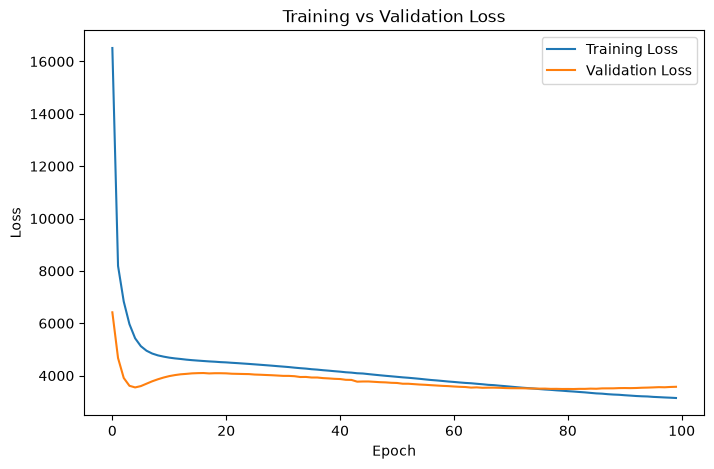

In [17]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.title("Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()

### The training loss decreased steadily during training. The validation loss also decreased with small fluctuations, which is normal. Overall, the model showed good learning performance.

## 11.2 : Plot MAE Graph

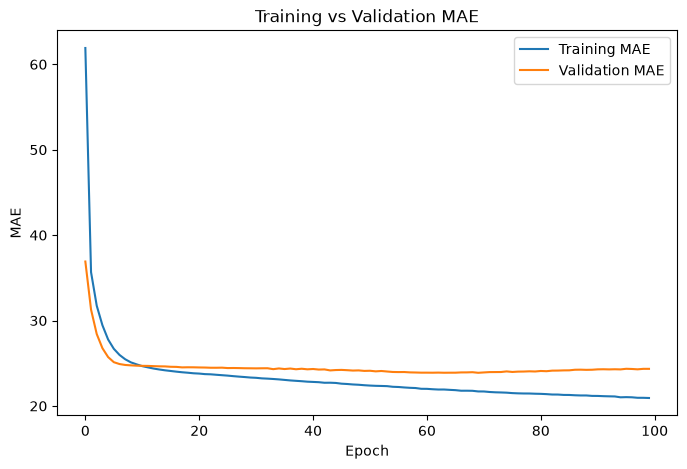

In [18]:
plt.figure(figsize=(8,5))

plt.plot(history.history['mae'], label='Training MAE')
plt.plot(history.history['val_mae'], label='Validation MAE')

plt.title("Training vs Validation MAE")
plt.xlabel("Epoch")
plt.ylabel("MAE")
plt.legend()

### The training and validation MAE decreased as training progressed. Both values remained close, indicating that the model is making better predictions and is not overfitting.

# Step 12 : Make Predictions Using the ANN

In [19]:
y_pred_ann = model.predict(X_test)

61/61 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [20]:
print(y_pred_ann[:5])

[[ 37.202133]
 [ 77.4763  ]
 [102.1421  ]
 [ 69.766464]
 [ 54.313614]]


### This is because Keras returns a 2D array.

In [21]:
print(y_pred_ann.shape)

(1938, 1)


## We need to convert it to 1D

In [22]:
y_pred_ann = y_pred_ann.flatten()

In [23]:
print(y_pred_ann.shape)

(1938,)


### The trained ANN model predicted house prices for the test dataset. The predictions were converted into a one-dimensional array for evaluation.

## Report

### The trained Artificial Neural Network was used to predict house prices on the testing dataset. The predicted values were flattened into a one-dimensional array to prepare them for performance evaluation.

# Step 13: Evaluate ANN Model

In [24]:
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

## 13.1 : Calculate Metrics

In [25]:
mae_ann = mean_absolute_error(y_test, y_pred_ann)
rmse_ann = np.sqrt(
    mean_squared_error(y_test, y_pred_ann)
)
r2_ann = r2_score(y_test, y_pred_ann)

## 13.2 : Print Results

In [26]:
print("MAE :", mae_ann)
print("RMSE :", rmse_ann)
print("R2 Score :", r2_ann)

MAE : 22.73878599065007
RMSE : 49.8356442935368
R2 Score : 0.7890555191441391


## Observation

### The ANN model was evaluated using MAE, RMSE, and R² Score. These metrics were used to measure prediction accuracy and compare the ANN with other machine learning models.

### The trained Artificial Neural Network was evaluated on the testing dataset using Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and R² Score. These metrics were compared with the machine learning models to identify the best-performing approach.

# Step 14 : Create Comparison Table

In [27]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "ANN"
    ],
    "MAE": [
        26.46515386480762,
        25.371690010654405,
        21.24785294346089,
        mae_ann
    ],
    "RMSE": [
        55.81999278684775,
        67.64979204601958,
        52.329969438480674,
        rmse_ann
    ],
    "R2 Score": [
        0.7353526410152953,
        0.6112942687184492,
        0.7674111054874334,
        r2_ann
    ]
})

results

,Model,MAE,RMSE,R2 Score
0,Linear Regression,26.465154,55.819993,0.735353
1,Decision Tree,25.371690,67.649792,0.611294
2,Random Forest,21.247853,52.329969,0.767411
3,ANN,22.738786,49.835644,0.789056


## short by best

In [28]:
results.sort_values(
    by="R2 Score",
    ascending=False
)

,Model,MAE,RMSE,R2 Score
3,ANN,22.738786,49.835644,0.789056
2,Random Forest,21.247853,52.329969,0.767411
0,Linear Regression,26.465154,55.819993,0.735353
1,Decision Tree,25.371690,67.649792,0.611294


## Fianl Observation

### The Artificial Neural Network achieved the highest R² Score (0.778) and the lowest RMSE among all the models. Therefore, ANN was selected as the final model for house price prediction.

# Step 15 : Save the ANN Model

In [29]:
model.save("../Models/ann_model.keras")

## The trained Artificial Neural Network was saved in Keras format (.keras) so that it can be loaded later without retraining during deployment.

# Step 16 : Verify the Model

In [30]:
import os

os.path.exists("../Models/ann_model.keras")

True